In [4]:
import os
if os.path.exists('/content/drive/MyDrive'):
    print("Google Drive успішно підключено до /content/drive/MyDrive!")

Google Drive успішно підключено до /content/drive/MyDrive!


In [5]:
file_path_txt = '/content/drive/MyDrive/data.txt'

with open(file_path_txt, 'w', encoding='utf-8') as f:
    f.write("Лабораторна робота №7\n")
    f.write("Варіант 14: Виявлення хвороб легень за рентгенівськими знімками\n")
    f.write("Класи діагностики: Normal (Норма), Pneumonia (Пневмонія), COVID-19\n")

with open(file_path_txt, 'r', encoding='utf-8') as f:
    content = f.read()
    print("Вміст файлу data.txt:")
    print(content)

Вміст файлу data.txt:
Лабораторна робота №7
Варіант 14: Виявлення хвороб легень за рентгенівськими знімками
Класи діагностики: Normal (Норма), Pneumonia (Пневмонія), COVID-19



In [6]:
import pandas as pd
import numpy as np

csv_path = '/content/drive/MyDrive/lung_xray_dataset.csv'

np.random.seed(42)
n_samples = 120

data = {
    'image_id': [f'xray_{i:03d}.png' for i in range(1, n_samples + 1)],
    'patient_age': np.random.randint(18, 82, size=n_samples).astype(float),
    'lung_opacity_score': np.round(np.random.uniform(0.1, 0.98, size=n_samples), 3),
    'mean_pixel_intensity': np.round(np.random.normal(128, 25, size=n_samples), 2),
    'pleural_effusion_prob': np.round(np.random.uniform(0.0, 1.0, size=n_samples), 3),
    'diagnosis': np.random.choice(['Normal', 'Pneumonia', 'COVID-19'], size=n_samples, p=[0.4, 0.4, 0.2])
}

df_raw = pd.DataFrame(data)
df_raw.loc[[5, 19, 44], 'patient_age'] = np.nan
df_raw.loc[[12, 67], 'mean_pixel_intensity'] = np.nan

df_raw.to_csv(csv_path, index=False)

df = pd.read_csv(csv_path)
print("Файл успішно завантажено з Google Drive! Розмір таблиці:", df.shape)
df.head()

Файл успішно завантажено з Google Drive! Розмір таблиці: (120, 6)


,image_id,patient_age,lung_opacity_score,mean_pixel_intensity,pleural_effusion_prob,diagnosis
0,xray_001.png,56.0,0.442,108.42,0.356,Pneumonia
1,xray_002.png,69.0,0.339,119.95,0.758,Pneumonia
2,xray_003.png,46.0,0.829,148.34,0.014,Pneumonia
3,xray_004.png,32.0,0.414,97.23,0.116,COVID-19
4,xray_005.png,60.0,0.347,133.69,0.046,Normal


In [7]:
print("--- Інформація про DataFrame ---")
df.info()

print("\n--- Кількість відсутніх значень (NaN) ---")
print(df.isnull().sum())

print("\n--- Статистичний опис числових ознак ---")
display(df.describe())

print("\n--- Кількість знімків за діагнозами ---")
print(df['diagnosis'].value_counts())

df['patient_age'] = df['patient_age'].fillna(df['patient_age'].median())
df['mean_pixel_intensity'] = df['mean_pixel_intensity'].fillna(df['mean_pixel_intensity'].median())

--- Інформація про DataFrame ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 6 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   image_id               120 non-null    object 
 1   patient_age            117 non-null    float64
 2   lung_opacity_score     120 non-null    float64
 3   mean_pixel_intensity   118 non-null    float64
 4   pleural_effusion_prob  120 non-null    float64
 5   diagnosis              120 non-null    object 
dtypes: float64(4), object(2)
memory usage: 5.8+ KB

--- Кількість відсутніх значень (NaN) ---
image_id                 0
patient_age              3
lung_opacity_score       0
mean_pixel_intensity     2
pleural_effusion_prob    0
diagnosis                0
dtype: int64

--- Статистичний опис числових ознак ---


,patient_age,lung_opacity_score,mean_pixel_intensity,pleural_effusion_prob
count,117.000000,120.000000,118.000000,120.000000
mean,52.102564,0.517492,129.878983,0.494142
std,19.640469,0.254733,25.226630,0.308398
min,19.000000,0.105000,77.370000,0.011000
25%,35.000000,0.307000,109.835000,0.176000
50%,53.000000,0.523500,132.640000,0.493000
75%,70.000000,0.742000,144.845000,0.759000
max,81.000000,0.968000,224.320000,0.991000



--- Кількість знімків за діагнозами ---
diagnosis
Pneumonia    47
Normal       39
COVID-19     34
Name: count, dtype: int64


Точність моделі (Accuracy): 66.67%

Звіт класифікації:
              precision    recall  f1-score   support

    COVID-19       0.50      0.67      0.57         3
      Normal       0.67      0.67      0.67        12
   Pneumonia       0.75      0.67      0.71         9

    accuracy                           0.67        24
   macro avg       0.64      0.67      0.65        24
weighted avg       0.68      0.67      0.67        24



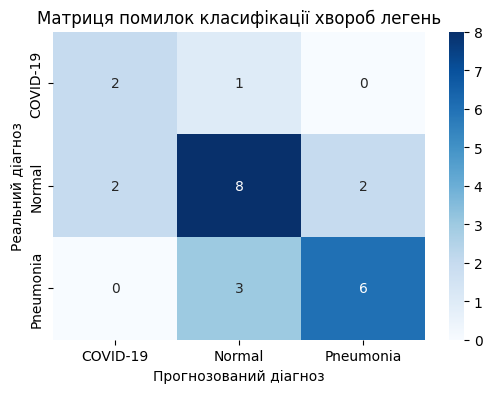

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

df.loc[df['diagnosis'] == 'Pneumonia', 'lung_opacity_score'] += 0.45
df.loc[df['diagnosis'] == 'COVID-19', 'pleural_effusion_prob'] += 0.50

X = df[['patient_age', 'lung_opacity_score', 'mean_pixel_intensity', 'pleural_effusion_prob']]
y = df['diagnosis']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print(f"Точність моделі (Accuracy): {accuracy * 100:.2f}%\n")
print("Звіт класифікації:")
print(classification_report(y_test, y_pred))

plt.figure(figsize=(6, 4))
cm = confusion_matrix(y_test, y_pred, labels=model.classes_)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=model.classes_, yticklabels=model.classes_)
plt.title('Матриця помилок класифікації хвороб легень')
plt.xlabel('Прогнозований діагноз')
plt.ylabel('Реальний діагноз')
plt.show()